,pair,method,weighted_accuracy,macro_accuracy
0,PairA,MOSCOT,43.20%,39.43%
1,PairA,SOCS,45.21%,45.53%
2,PairA,Ours,49.42%,48.72%
3,PairC,MOSCOT,43.29%,42.33%
4,PairC,SOCS,39.42%,38.25%
5,PairC,Ours,38.43%,42.74%


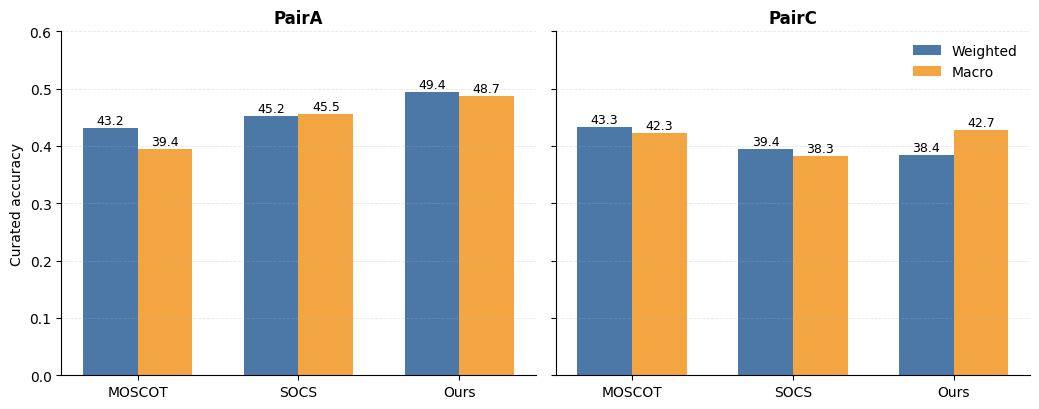


Selected MOSCOT:
PairA task 5 weighted 0.43204487897200755 macro 0.3942616063109945
PairC task 11 weighted 0.4329040822556589 macro 0.42330456204613753


In [ ]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/pareto")

MOSCOT_ROOT = {
    "PairA": Path("/mnt/disk2/lirui/mosta_growth_marginal_ablation/no_growth_score/E9.5_E1S1__E10.5_E2S1/results/E9.5_E1S1__E10.5_E2S1/X_nbvae_30"),
    "PairC": Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/moscot/E10.5__E11.5/X_nbvae_30"),
}

SOCS_ROOT = {
    "PairA": Path("/mnt/disk2/lirui/mosta_socs_official_unsupervised/PairA"),
    "PairC": Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/socs/PairC"),
}

OURS_ROOT = {
    "PairA": ROOT / "PairA/src1_tgt0p6/stage2",
    "PairC": ROOT / "PairC/src1_tgt0p6/stage2",
}

def best_moscot(root):
    rows = []
    for mp in sorted(root.glob("task_*/metrics.json")):
        m = json.loads(mp.read_text())
        if m.get("status") != "success":
            continue
        weighted = m.get("accuracy", m.get("weighted_accuracy"))
        macro = m.get("macro_curated_accuracy", m.get("macro_accuracy"))
        if weighted is None or macro is None:
            continue
        rows.append({
            "weighted": float(weighted), "macro": float(macro),
            "task_id": int(m["task_id"]), "task_dir": mp.parent,
        })
    if not rows:
        raise RuntimeError(f"No successful MOSCOT metrics under {root}")
    return pd.DataFrame(rows).sort_values(
        ["weighted","task_id"], ascending=[False,True]
    ).iloc[0]

def best_socs(root):
    grid = pd.read_csv(root / "grid_results.csv")
    row = grid.loc[grid["weighted_accuracy"].astype(float).idxmax()]
    return {
        "weighted": float(row["weighted_accuracy"]),
        "macro": float(row["macro_accuracy"]),
        "task_id": int(row["task_id"]),
        "task_dir": None,
    }

def ours_summary(root):
    hits = sorted(root.glob("*_summary.csv"))
    if len(hits) != 1:
        raise RuntimeError(f"Expected one summary under {root}, found {hits}")
    r = pd.read_csv(hits[0]).iloc[0]
    return {
        "weighted": float(r["mass_weighted"]),
        "macro": float(r["mass_macro"]),
    }

SELECTED = {}
rows = []

for pair in ["PairA","PairC"]:
    m = best_moscot(MOSCOT_ROOT[pair])
    s = best_socs(SOCS_ROOT[pair])
    o = ours_summary(OURS_ROOT[pair])

    SELECTED[pair] = {"MOSCOT":m, "SOCS":s, "Ours":o}

    for method, r in [("MOSCOT",m),("SOCS",s),("Ours",o)]:
        rows.append({
            "pair":pair, "method":method,
            "weighted_accuracy":r["weighted"],
            "macro_accuracy":r["macro"],
        })

BENCHMARK = pd.DataFrame(rows)

display(BENCHMARK.style.format({
    "weighted_accuracy":"{:.2%}",
    "macro_accuracy":"{:.2%}",
}))

fig, axes = plt.subplots(1,2,figsize=(10.5,4.2),sharey=True)
methods = ["MOSCOT","SOCS","Ours"]
colors = ["#4C78A8","#F2A541"]

for ax, pair in zip(axes, ["PairA","PairC"]):
    d = BENCHMARK[BENCHMARK.pair==pair].set_index("method").loc[methods]
    x = np.arange(3); w = .34
    b1 = ax.bar(x-w/2,d.weighted_accuracy,w,color=colors[0],label="Weighted")
    b2 = ax.bar(x+w/2,d.macro_accuracy,w,color=colors[1],label="Macro")
    for bars in [b1,b2]:
        for b in bars:
            ax.text(b.get_x()+b.get_width()/2,b.get_height()+.007,
                    f"{100*b.get_height():.1f}",ha="center",fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(methods)
    ax.set_ylim(0,.60)
    ax.set_title(pair,fontweight="bold")
    ax.grid(axis="y",ls="--",lw=.6,alpha=.3)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Curated accuracy")
axes[1].legend(frameon=False)
fig.tight_layout()

out = ROOT/"MOSCOT_SOCS_Ours_mass_accuracy.png"
fig.savefig(out,dpi=300,bbox_inches="tight")
plt.show()

print("\nSelected MOSCOT:")

for p in ["PairA","PairC"]:
    print(p, "task", int(SELECTED[p]["MOSCOT"]["task_id"]),
          "weighted", SELECTED[p]["MOSCOT"]["weighted"],
          "macro", SELECTED[p]["MOSCOT"]["macro"])

In [3]:
import anndata as ad

PAIR_DATA = {
    "PairA": {
        "source": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_source_E9.5_E1S1.h5ad"),
        "target": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_target_E10.5_E2S1.h5ad"),
    },
    "PairC": {
        "source": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E10.5_E2S1.nbvae30.h5ad"),
        "target": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E11.5_E1S1.nbvae30.h5ad"),
    },
}

CURATED = Path("/mnt/disk2/lirui/baseline_scripts/mosta_flatvi_fgw/MOSTA_curated_transitions.tsv")

def split_desc(x):
    x = str(x)
    if x.lower()=="nan": return []
    return [z.strip() for z in re.split(r"[,;|\n]+",x) if z.strip() and z.strip()!="/"]

def load_allowed():
    df = pd.read_csv(CURATED,sep=None,engine="python")
    out = {}
    for _,r in df.iterrows():
        s = str(r["Cell_type"]).strip()
        if not s or s.lower()=="nan": continue
        out[s] = {s}|set(split_desc(r["Known_descendants"]))
    return out

ALLOWED = load_allowed()

def read_names(path):
    return np.atleast_1d(np.loadtxt(path,dtype=str)).astype(str)

def align_annotations(adata,names):
    idx = pd.Index(adata.obs_names.astype(str)).get_indexer(names)
    if np.any(idx<0) and "original_obs_name" in adata.obs:
        idx = pd.Index(adata.obs["original_obs_name"].astype(str)).get_indexer(names)
    if np.any(idx<0):
        raise KeyError(f"Cannot align names: {names[idx<0][:5]}")
    return adata.obs["annotation"].astype(str).to_numpy()[idx]

def dense_mass_table(P_path, source, target, source_names_path, target_names_path):
    P = np.load(P_path,mmap_mode="r")
    sn = read_names(source_names_path); tn = read_names(target_names_path)
    sa = align_annotations(source,sn); ta = align_annotations(target,tn)

    s_types = np.unique(sa); t_types = np.unique(ta)
    mass = pd.DataFrame(0.0,index=s_types,columns=t_types)

    for s in s_types:
        ii = np.flatnonzero(sa==s)
        target_mass = np.asarray(P[ii,:],dtype=np.float64).sum(axis=0)
        for t in t_types:
            mass.loc[s,t] = target_mass[ta==t].sum()
    return mass

def sparse_ours_mass_table(stage2_dir, source, target):
    hits = sorted(stage2_dir.glob("*_transport_sparse.npz"))
    if len(hits)!=1: raise RuntimeError(hits)
    S = np.load(hits[0])
    offsets = S["row_offsets"]
    tgt_idx = S["target_indices"]
    mass = S["mass"]

    sa = source.obs["annotation"].astype(str).to_numpy()
    ta = target.obs["annotation"].astype(str).to_numpy()
    s_types = np.unique(sa); t_types = np.unique(ta)
    out = pd.DataFrame(0.0,index=s_types,columns=t_types)

    for i in range(source.n_obs):
        lo,hi = offsets[i],offsets[i+1]
        if hi<=lo: continue
        vals = mass[lo:hi]
        jj = tgt_idx[lo:hi]
        for t in np.unique(ta[jj]):
            out.loc[sa[i],t] += vals[ta[jj]==t].sum()
    return out

def per_type_accuracy(mass):
    rows = []
    for s,row in mass.iterrows():
        total = float(row.sum())
        viable = ALLOWED.get(str(s),{str(s)})
        correct = float(row[[t for t in row.index if t in viable]].sum())
        rows.append({
            "source_annotation":str(s),
            "total_mass":total,
            "accuracy":correct/total if total>0 else np.nan,
        })
    return pd.DataFrame(rows)

CELLTYPE_ROWS = []

for pair in ["PairA","PairC"]:
    source = ad.read_h5ad(PAIR_DATA[pair]["source"])
    target = ad.read_h5ad(PAIR_DATA[pair]["target"])

    # MOSCOT weighted-best selected in Cell 1
    md = SELECTED[pair]["MOSCOT"]["task_dir"]
    M_m = dense_mass_table(
        md/"transport.npy",source,target,
        md/"source_obs_names.txt",md/"target_obs_names.txt"
    )

    # SOCS weighted-best
    sd = SOCS_ROOT[pair]
    M_s = dense_mass_table(
        sd/"best_transport.npy",source,target,
        sd/"source_obs_names.txt",sd/"target_obs_names.txt"
    )

    M_o = sparse_ours_mass_table(OURS_ROOT[pair],source,target)

    tables = {
        "MOSCOT":per_type_accuracy(M_m),
        "SOCS":per_type_accuracy(M_s),
        "Ours":per_type_accuracy(M_o),
    }

    base = pd.DataFrame({
        "source_annotation":np.unique(source.obs["annotation"].astype(str)),
        "n_source":[
            int((source.obs["annotation"].astype(str)==x).sum())
            for x in np.unique(source.obs["annotation"].astype(str))
        ]
    })

    for method,t in tables.items():
        base = base.merge(
            t[["source_annotation","accuracy"]].rename(columns={"accuracy":method}),
            on="source_annotation",how="left"
        )

    base["best_baseline"] = base[["MOSCOT","SOCS"]].max(axis=1)
    base["ours_minus_best_baseline"] = base["Ours"]-base["best_baseline"]
    base.insert(0,"pair",pair)
    CELLTYPE_ROWS.append(base)

CELLTYPE_TABLE = pd.concat(CELLTYPE_ROWS,ignore_index=True)

display(
    CELLTYPE_TABLE[
        CELLTYPE_TABLE.source_annotation!="Cavity"
    ].sort_values(
        ["pair","ours_minus_best_baseline"],
        ascending=[True,False]
    ).style.format({
        "MOSCOT":"{:.1%}","SOCS":"{:.1%}","Ours":"{:.1%}",
        "best_baseline":"{:.1%}",
        "ours_minus_best_baseline":"{:+.1%}",
    })
)

,pair,source_annotation,n_source,MOSCOT,SOCS,Ours,best_baseline,ours_minus_best_baseline
4,PairA,Connective tissue,283,34.3%,34.3%,65.0%,34.3%,+30.7%
11,PairA,Sclerotome,244,47.9%,61.1%,81.8%,61.1%,+20.7%
10,PairA,Notochord,236,2.6%,5.5%,12.3%,5.5%,+6.8%
1,PairA,Brain,1518,64.1%,49.5%,67.3%,64.1%,+3.2%
6,PairA,Heart,382,94.5%,95.0%,97.1%,95.0%,+2.1%
7,PairA,Liver,98,22.4%,24.5%,26.5%,24.5%,+2.0%
9,PairA,Neural crest,1008,31.0%,31.3%,31.9%,31.3%,+0.6%
8,PairA,Mesenchyme,337,61.7%,84.0%,84.2%,84.0%,+0.3%
0,PairA,AGM,452,18.1%,18.8%,15.5%,18.8%,-3.4%
2,PairA,Branchial arch,200,37.0%,48.0%,37.0%,48.0%,-11.0%


In [4]:
# ============================================================
# REPLACEMENT CELL:
# per-cell-type comparison with THREE SEPARATE METRICS
#
# 1) active_fraction
# 2) all-source curated-valid top1 accuracy
# 3) curated-valid transport-mass accuracy
#
# IMPORTANT:
#   inactive / zero-mass source rows count as WRONG
#   in all-source top1 accuracy.
#
# Nothing is saved.
#
# Requires these path/config objects already defined:
#   PAIR_DATA
#   SELECTED
#   SOCS_ROOT
#   OURS_ROOT
#   ALLOWED
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
from IPython.display import display


# ============================================================
# 1. NAME ALIGNMENT
# ============================================================

def read_names(path):
    return np.atleast_1d(
        np.loadtxt(path, dtype=str)
    ).astype(str)


def align_to_adata(adata, saved_names):
    """
    Return CURRENT adata row indices corresponding to saved_names.
    """

    current = adata.obs_names.astype(str)

    idx = pd.Index(current).get_indexer(
        saved_names
    )

    if (
        np.any(idx < 0)
        and "original_obs_name" in adata.obs.columns
    ):
        original = (
            adata.obs["original_obs_name"]
            .astype(str)
            .to_numpy()
        )

        idx = pd.Index(original).get_indexer(
            saved_names
        )

    if np.any(idx < 0):
        bad = saved_names[idx < 0][:5]
        raise KeyError(
            f"Cannot align saved names, examples: {bad}"
        )

    return idx.astype(np.int64)


# ============================================================
# 2. DENSE TRANSPORT:
#    return top1 in CURRENT source/target indexing
#    + annotation-level mass table
# ============================================================

def load_dense_transport_stats(
    P_path,
    source,
    target,
    source_names_path,
    target_names_path,
    block_size=512,
):

    P = np.load(
        P_path,
        mmap_mode="r",
    )

    saved_src = read_names(
        source_names_path
    )

    saved_tgt = read_names(
        target_names_path
    )

    if P.shape != (
        len(saved_src),
        len(saved_tgt),
    ):
        raise ValueError(
            f"{P_path}\n"
            f"P shape={P.shape}, "
            f"names={(len(saved_src), len(saved_tgt))}"
        )

    # current H5AD indices
    src_current_idx = align_to_adata(
        source,
        saved_src,
    )

    tgt_current_idx = align_to_adata(
        target,
        saved_tgt,
    )

    src_ann_current = (
        source.obs["annotation"]
        .astype(str)
        .to_numpy()
    )

    tgt_ann_current = (
        target.obs["annotation"]
        .astype(str)
        .to_numpy()
    )

    # annotations in SAVED transport order
    src_ann_saved = src_ann_current[
        src_current_idx
    ]

    tgt_ann_saved = tgt_ann_current[
        tgt_current_idx
    ]

    ns = source.n_obs

    top1 = np.full(
        ns,
        -1,
        dtype=np.int32,
    )

    row_mass_current = np.zeros(
        ns,
        dtype=np.float64,
    )

    # --------------------------------------------------------
    # top1
    # --------------------------------------------------------

    for lo in range(
        0,
        P.shape[0],
        block_size,
    ):

        hi = min(
            lo + block_size,
            P.shape[0],
        )

        B = np.asarray(
            P[lo:hi],
            dtype=np.float64,
        )

        rm = B.sum(axis=1)

        current_rows = src_current_idx[
            lo:hi
        ]

        row_mass_current[
            current_rows
        ] = rm

        active = (
            np.isfinite(rm)
            &
            (rm > 0)
        )

        if np.any(active):

            local_rows = np.flatnonzero(
                active
            )

            saved_target_col = np.argmax(
                B[local_rows],
                axis=1,
            )

            current_target = tgt_current_idx[
                saved_target_col
            ]

            top1[
                current_rows[local_rows]
            ] = current_target

    # --------------------------------------------------------
    # annotation-level transported mass
    # --------------------------------------------------------

    s_types = np.unique(
        src_ann_saved
    )

    t_types = np.unique(
        tgt_ann_saved
    )

    mass_table = pd.DataFrame(
        0.0,
        index=s_types,
        columns=t_types,
    )

    for s in s_types:

        ii = np.flatnonzero(
            src_ann_saved == s
        )

        target_mass = np.asarray(
            P[ii, :],
            dtype=np.float64,
        ).sum(axis=0)

        for t in t_types:

            mass_table.loc[
                s, t
            ] = target_mass[
                tgt_ann_saved == t
            ].sum()

    return {
        "top1": top1,
        "row_mass": row_mass_current,
        "mass_table": mass_table,
    }


# ============================================================
# 3. OUR SPARSE TRANSPORT
# ============================================================

def load_sparse_ours_stats(
    stage2_dir,
    source,
    target,
):

    hits = sorted(
        Path(stage2_dir).glob(
            "*_transport_sparse.npz"
        )
    )

    if len(hits) != 1:
        raise RuntimeError(
            f"Expected exactly one sparse transport under "
            f"{stage2_dir}\nFound: {hits}"
        )

    S = np.load(
        hits[0]
    )

    offsets = np.asarray(
        S["row_offsets"],
        dtype=np.int64,
    )

    target_indices = np.asarray(
        S["target_indices"],
        dtype=np.int32,
    )

    mass = np.asarray(
        S["mass"],
        dtype=np.float64,
    )

    ns = source.n_obs
    nt = target.n_obs

    if len(offsets) != ns + 1:
        raise ValueError(
            f"Ours sparse rows={len(offsets)-1}, "
            f"source n={ns}"
        )

    src_ann = (
        source.obs["annotation"]
        .astype(str)
        .to_numpy()
    )

    tgt_ann = (
        target.obs["annotation"]
        .astype(str)
        .to_numpy()
    )

    top1 = np.full(
        ns,
        -1,
        dtype=np.int32,
    )

    row_mass = np.zeros(
        ns,
        dtype=np.float64,
    )

    s_types = np.unique(
        src_ann
    )

    t_types = np.unique(
        tgt_ann
    )

    mass_table = pd.DataFrame(
        0.0,
        index=s_types,
        columns=t_types,
    )

    for i in range(ns):

        lo = offsets[i]
        hi = offsets[i + 1]

        if hi <= lo:
            continue

        vals = mass[
            lo:hi
        ]

        jj = target_indices[
            lo:hi
        ]

        rm = float(
            vals.sum()
        )

        row_mass[i] = rm

        if (
            np.isfinite(rm)
            and
            rm > 0
        ):
            top1[i] = jj[
                np.argmax(vals)
            ]

        # annotation mass
        labs = tgt_ann[
            jj
        ]

        for t in np.unique(
            labs
        ):
            mass_table.loc[
                src_ann[i],
                t
            ] += vals[
                labs == t
            ].sum()

    return {
        "top1": top1,
        "row_mass": row_mass,
        "mass_table": mass_table,
    }


# ============================================================
# 4. PER-ORGAN METRICS
# ============================================================

def per_type_metrics(
    source,
    target,
    stats,
):

    src_ann = (
        source.obs["annotation"]
        .astype(str)
        .to_numpy()
    )

    tgt_ann = (
        target.obs["annotation"]
        .astype(str)
        .to_numpy()
    )

    top1 = stats[
        "top1"
    ]

    row_mass = stats[
        "row_mass"
    ]

    mass_table = stats[
        "mass_table"
    ]

    rows = []

    for s in sorted(
        np.unique(src_ann)
    ):

        ii = np.flatnonzero(
            src_ann == s
        )

        n_source = len(ii)

        # ----------------------------------------------------
        # active source
        # ----------------------------------------------------

        active_mask = (
            np.isfinite(
                row_mass[ii]
            )
            &
            (
                row_mass[ii]
                >
                0
            )
            &
            (
                top1[ii]
                >=
                0
            )
        )

        active_idx = ii[
            active_mask
        ]

        n_active = len(
            active_idx
        )

        active_fraction = (
            n_active
            /
            n_source
        )

        # ----------------------------------------------------
        # ALL-SOURCE curated-valid top1
        #
        # Start every source as False.
        # Inactive source therefore remains incorrect.
        # ----------------------------------------------------

        viable = ALLOWED.get(
            str(s),
            {str(s)},
        )

        correct_all = np.zeros(
            n_source,
            dtype=bool,
        )

        if n_active > 0:

            active_positions = np.flatnonzero(
                active_mask
            )

            endpoint_labels = tgt_ann[
                top1[
                    active_idx
                ]
            ]

            correct_all[
                active_positions
            ] = np.asarray(
                [
                    str(x) in viable
                    for x in endpoint_labels
                ],
                dtype=bool,
            )

        top1_allsource = float(
            correct_all.mean()
        )

        n_top1_correct = int(
            correct_all.sum()
        )

        # ----------------------------------------------------
        # optional: conditional accuracy among active only
        # useful for diagnosis, NOT primary accuracy
        # ----------------------------------------------------

        top1_active_only = (
            n_top1_correct
            /
            n_active
            if n_active > 0
            else np.nan
        )

        # ----------------------------------------------------
        # transported-mass accuracy
        # ----------------------------------------------------

        if s in mass_table.index:

            mass_row = mass_table.loc[
                s
            ]

            total_mass = float(
                mass_row.sum()
            )

            viable_cols = [
                t
                for t in mass_row.index
                if str(t) in viable
            ]

            correct_mass = float(
                mass_row[
                    viable_cols
                ].sum()
            )

            mass_accuracy = (
                correct_mass
                /
                total_mass
                if total_mass > 0
                else np.nan
            )

        else:

            total_mass = 0.0
            correct_mass = 0.0
            mass_accuracy = np.nan

        rows.append({
            "source_annotation":
                str(s),

            "n_source":
                n_source,

            "n_active":
                n_active,

            "active_fraction":
                active_fraction,

            "n_top1_correct":
                n_top1_correct,

            "top1_allsource":
                top1_allsource,

            "top1_active_only":
                top1_active_only,

            "mass_accuracy":
                mass_accuracy,

            "total_transport_mass":
                total_mass,
        })

    return pd.DataFrame(
        rows
    )


# ============================================================
# 5. RUN BOTH PAIRS
# ============================================================

ALL_ROWS = []


for pair in [
    "PairA",
    "PairC",
]:

    print(
        "\n"
        + "=" * 100
    )
    print(pair)
    print("=" * 100)

    source = ad.read_h5ad(
        PAIR_DATA[
            pair
        ][
            "source"
        ]
    )

    target = ad.read_h5ad(
        PAIR_DATA[
            pair
        ][
            "target"
        ]
    )

    # --------------------------------------------------------
    # MOSCOT
    # --------------------------------------------------------

    md = SELECTED[
        pair
    ][
        "MOSCOT"
    ][
        "task_dir"
    ]

    moscot_stats = (
        load_dense_transport_stats(
            md / "transport.npy",
            source,
            target,
            md / "source_obs_names.txt",
            md / "target_obs_names.txt",
        )
    )

    # --------------------------------------------------------
    # SOCS
    # --------------------------------------------------------

    sd = SOCS_ROOT[
        pair
    ]

    socs_stats = (
        load_dense_transport_stats(
            sd / "best_transport.npy",
            source,
            target,
            sd / "source_obs_names.txt",
            sd / "target_obs_names.txt",
        )
    )

    # --------------------------------------------------------
    # OURS
    # --------------------------------------------------------

    ours_stats = (
        load_sparse_ours_stats(
            OURS_ROOT[
                pair
            ],
            source,
            target,
        )
    )

    method_stats = {
        "MOSCOT":
            moscot_stats,

        "SOCS":
            socs_stats,

        "Ours":
            ours_stats,
    }

    pair_table = None

    for method, stats in (
        method_stats.items()
    ):

        t = per_type_metrics(
            source,
            target,
            stats,
        )

        t = t.rename(
            columns={
                "n_active":
                    f"{method}_n_active",

                "active_fraction":
                    f"{method}_active",

                "n_top1_correct":
                    f"{method}_n_correct",

                "top1_allsource":
                    f"{method}_top1",

                "top1_active_only":
                    f"{method}_top1_active_only",

                "mass_accuracy":
                    f"{method}_mass",

                "total_transport_mass":
                    f"{method}_transport_mass",
            }
        )

        keep = [
            "source_annotation",
            "n_source",

            f"{method}_n_active",
            f"{method}_active",

            f"{method}_n_correct",
            f"{method}_top1",

            f"{method}_top1_active_only",
            f"{method}_mass",
        ]

        t = t[
            keep
        ]

        if pair_table is None:

            pair_table = t

        else:

            pair_table = (
                pair_table.merge(
                    t.drop(
                        columns=[
                            "n_source"
                        ]
                    ),
                    on="source_annotation",
                    how="outer",
                )
            )

    pair_table.insert(
        0,
        "pair",
        pair,
    )

    # --------------------------------------------------------
    # PRIMARY COMPARISON =
    # ALL-SOURCE TOP1
    # --------------------------------------------------------

    pair_table[
        "best_baseline_top1"
    ] = pair_table[
        [
            "MOSCOT_top1",
            "SOCS_top1",
        ]
    ].max(
        axis=1
    )

    pair_table[
        "ours_minus_best_baseline_top1"
    ] = (
        pair_table[
            "Ours_top1"
        ]
        -
        pair_table[
            "best_baseline_top1"
        ]
    )

    ALL_ROWS.append(
        pair_table
    )


CELLTYPE_TABLE_CORRECTED = (
    pd.concat(
        ALL_ROWS,
        ignore_index=True,
    )
)


# ============================================================
# 6. PRIMARY TABLE
#
# This is the table to use for method comparison.
# ============================================================

PRIMARY_COLS = [
    "pair",
    "source_annotation",
    "n_source",

    "MOSCOT_active",
    "SOCS_active",
    "Ours_active",

    "MOSCOT_top1",
    "SOCS_top1",
    "Ours_top1",

    "MOSCOT_mass",
    "SOCS_mass",
    "Ours_mass",

    "best_baseline_top1",
    "ours_minus_best_baseline_top1",
]


display(
    CELLTYPE_TABLE_CORRECTED[
        CELLTYPE_TABLE_CORRECTED[
            "source_annotation"
        ]
        !=
        "Cavity"
    ]
    .sort_values(
        [
            "pair",
            "ours_minus_best_baseline_top1",
        ],
        ascending=[
            True,
            False,
        ],
    )[
        PRIMARY_COLS
    ]
    .style
    .format({

        "MOSCOT_active":
            "{:.1%}",
        "SOCS_active":
            "{:.1%}",
        "Ours_active":
            "{:.1%}",

        "MOSCOT_top1":
            "{:.1%}",
        "SOCS_top1":
            "{:.1%}",
        "Ours_top1":
            "{:.1%}",

        "MOSCOT_mass":
            "{:.1%}",
        "SOCS_mass":
            "{:.1%}",
        "Ours_mass":
            "{:.1%}",

        "best_baseline_top1":
            "{:.1%}",

        "ours_minus_best_baseline_top1":
            "{:+.1%}",
    })
)


# ============================================================
# 7. SANITY CHECK: PAIRC LIVER
# ============================================================

print(
    "\n"
    + "=" * 100
)
print(
    "SANITY CHECK | PairC Liver"
)
print(
    "=" * 100
)

display(
    CELLTYPE_TABLE_CORRECTED[
        (
            CELLTYPE_TABLE_CORRECTED[
                "pair"
            ]
            ==
            "PairC"
        )
        &
        (
            CELLTYPE_TABLE_CORRECTED[
                "source_annotation"
            ]
            ==
            "Liver"
        )
    ][
        [
            "n_source",

            "MOSCOT_n_active",
            "MOSCOT_n_correct",
            "MOSCOT_active",
            "MOSCOT_top1",
            "MOSCOT_top1_active_only",
            "MOSCOT_mass",

            "SOCS_n_active",
            "SOCS_n_correct",
            "SOCS_active",
            "SOCS_top1",
            "SOCS_top1_active_only",
            "SOCS_mass",

            "Ours_n_active",
            "Ours_n_correct",
            "Ours_active",
            "Ours_top1",
            "Ours_top1_active_only",
            "Ours_mass",
        ]
    ]
    .style
    .format({

        "MOSCOT_active":
            "{:.1%}",
        "MOSCOT_top1":
            "{:.1%}",
        "MOSCOT_top1_active_only":
            "{:.1%}",
        "MOSCOT_mass":
            "{:.1%}",

        "SOCS_active":
            "{:.1%}",
        "SOCS_top1":
            "{:.1%}",
        "SOCS_top1_active_only":
            "{:.1%}",
        "SOCS_mass":
            "{:.1%}",

        "Ours_active":
            "{:.1%}",
        "Ours_top1":
            "{:.1%}",
        "Ours_top1_active_only":
            "{:.1%}",
        "Ours_mass":
            "{:.1%}",
    })
)


PairA

PairC


,pair,source_annotation,n_source,MOSCOT_active,SOCS_active,Ours_active,MOSCOT_top1,SOCS_top1,Ours_top1,MOSCOT_mass,SOCS_mass,Ours_mass,best_baseline_top1,ours_minus_best_baseline_top1
4,PairA,Connective tissue,283,100.0%,100.0%,100.0%,34.3%,34.3%,65.0%,34.3%,34.3%,65.0%,34.3%,+30.7%
11,PairA,Sclerotome,244,100.0%,100.0%,100.0%,48.0%,61.1%,82.0%,47.9%,61.1%,81.8%,61.1%,+20.9%
10,PairA,Notochord,236,100.0%,100.0%,100.0%,2.5%,5.5%,12.3%,2.6%,5.5%,12.3%,5.5%,+6.8%
1,PairA,Brain,1518,100.0%,100.0%,100.0%,64.2%,49.5%,67.3%,64.1%,49.5%,67.3%,64.2%,+3.2%
6,PairA,Heart,382,100.0%,100.0%,100.0%,94.5%,95.0%,97.1%,94.5%,95.0%,97.1%,95.0%,+2.1%
7,PairA,Liver,98,100.0%,100.0%,100.0%,22.4%,24.5%,26.5%,22.4%,24.5%,26.5%,24.5%,+2.0%
9,PairA,Neural crest,1008,100.0%,100.0%,100.0%,31.0%,31.3%,31.9%,31.0%,31.3%,31.9%,31.3%,+0.6%
8,PairA,Mesenchyme,337,100.0%,100.0%,100.0%,61.7%,84.0%,84.3%,61.7%,84.0%,84.2%,84.0%,+0.3%
0,PairA,AGM,452,100.0%,100.0%,100.0%,18.1%,18.8%,15.5%,18.1%,18.8%,15.5%,18.8%,-3.3%
2,PairA,Branchial arch,200,100.0%,100.0%,100.0%,37.0%,48.0%,37.0%,37.0%,48.0%,37.0%,48.0%,-11.0%



SANITY CHECK | PairC Liver


,n_source,MOSCOT_n_active,MOSCOT_n_correct,MOSCOT_active,MOSCOT_top1,MOSCOT_top1_active_only,MOSCOT_mass,SOCS_n_active,SOCS_n_correct,SOCS_active,SOCS_top1,SOCS_top1_active_only,SOCS_mass,Ours_n_active,Ours_n_correct,Ours_active,Ours_top1,Ours_top1_active_only,Ours_mass
22,143,107,97,74.8%,67.8%,90.7%,90.6%,78,72,54.5%,50.3%,92.3%,94.5%,143,127,100.0%,88.8%,88.8%,88.8%
